# FMUCD: explore the data

We are using maintenance work orders to test whether descriptions and historical task information can help group similar work and predict duration. We first check the data, then prepare the text and aggregate fields for clustering. `WODuration` measures elapsed days, not labor hours.

Source: [Pampana et al. (2024), FMUCD V1](https://data.mendeley.com/datasets/cb8d2nsjss/1), CC BY 4.0.

## Fields we will use

| Fields | Use |
| --- | --- |
| `UniversityID`, state/province | Compare reporting practices and locations. |
| `WODescription` and classification descriptions | Build the two text inputs. |
| System, subsystem, and component codes | Compare learned families with existing categories. |
| `PPM/UPM`, `WOPriority` | Describe maintenance type and local priority. |
| Building size, use, and construction year | Test additional context where available. |
| Start/end dates and `WODuration` | Check duration and create chronological splits. |
| Labor hours and costs | Check completed-work outcomes; exclude from initial-duration predictors. |

Priority codes may differ by university. Building condition and weather remain secondary because their availability at prediction time is uncertain.

## 1. Check the records

We check field coverage and duplicates before deciding which records to use. Only exact duplicate rows are removed here; repeated university/order IDs remain flagged for review.

In [54]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': False})
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'data/FMUCD.csv').exists() else Path.cwd() / 'fmucd_analysis'
DATA_PATH = PROJECT_DIR / 'data/FMUCD.csv'
OUTPUT_DIR = PROJECT_DIR / 'data/clustering'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
id_columns = ['UniversityID', 'BuildingID', 'WOID', 'WOPriority',
              'SystemCode', 'SubsystemCode', 'DescriptiveCode']

In [55]:
df_raw = pd.read_csv(DATA_PATH, dtype={c: 'string' for c in id_columns}, low_memory=False)
exact_duplicate_count = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().copy()
df.insert(0, 'record_id', df.index.astype('int64'))
text_columns = ['WODescription', 'SystemDescription', 'SubsystemDescription', 'ComponentDescription']
for column in text_columns:
    df[column] = df[column].astype('string').str.strip().replace('', pd.NA)
numeric_columns = ['WODuration', 'LaborHours', 'LaborCost', 'MaterialCost', 'OtherCost',
                   'TotalCost', 'Size', 'BuiltYear', 'FCI (facility condition index)',
                   'CRV (current replacement value)', 'DMC (deferred maintenance cost)']
parse_failures = {}
for column in numeric_columns:
    original_values = df[column]
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

In [56]:
df_raw.shape, df.shape

((3731442, 38), (3248897, 39))

In [57]:
for column in ['WOStartDate', 'WOEndDate']:
    original_values = df[column]
    df[column] = pd.to_datetime(original_values, format='mixed', errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())
df['duplicate_order_key'] = df.duplicated(['UniversityID', 'WOID'], keep=False)
df['missing_order_key'] = df[['UniversityID', 'WOID']].isna().any(axis=1)
field_quality = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_rows': df_raw.isna().sum(),
    'missing_pct': df_raw.isna().mean().mul(100).round(2),
    'unique_nonmissing': df_raw.nunique(dropna=True),
}).sort_values('missing_pct', ascending=False)
df.head(3)

,record_id,UniversityID,Country,State/Province,BuildingID,BuildingName,Size,Type,BuiltYear,FCI (facility condition index),...,MaxTemp.(°C),Atmospheric pressure(hPa),Humidity(%),WindSpeed(m/s),WindDegree,Precipitation(mm),Snow(mm),Cloudness(%),duplicate_order_key,missing_order_key
0,0,1,Canada,Nova Scotia,A050,COBURG ROAD 6414,5529.0,Research,1942.0,0.786664,...,0.299583,1023.291667,82.541667,2.379167,170.583333,0.0,0.00,87.583333,False,False
1,1,1,Canada,Nova Scotia,<NA>,NaN,NaN,NaN,NaN,NaN,...,-0.784167,998.125000,75.625000,4.229167,278.541667,0.0,0.11,77.500000,False,False
2,2,1,Canada,Nova Scotia,C201,LSC-BIOL&EARTH,161395.0,Mixed Teaching/Research,1971.0,0.449394,...,-1.926667,1017.250000,84.208333,1.924167,254.833333,0.0,4.42,88.375000,False,False


In [58]:
field_quality

,dtype,missing_rows,missing_pct,unique_nonmissing
FCI (facility condition index),float64,3304007,88.55,359
Size,float64,3301669,88.48,380
Type,object,3301669,88.48,23
CRV (current replacement value),float64,3301669,88.48,378
DMC (deferred maintenance cost),object,3301669,88.48,338
OtherCost,float64,3087808,82.75,31308
BuiltYear,float64,2844048,76.22,126
MaterialCost,float64,2687497,72.02,117544
BuildingName,object,2294841,61.50,2585
Cloudness(%),float64,2007402,53.80,2201


In [59]:
pd.Series(parse_failures, name='Values not parsed').to_frame()

,Values not parsed
WODuration,0
LaborHours,0
LaborCost,0
MaterialCost,0
OtherCost,0
TotalCost,0
Size,0
BuiltYear,0
FCI (facility condition index),0
CRV (current replacement value),0


We removed 482,545 exact duplicates. Repeated university/order IDs still need separate review.

## 2. Check the duration target

We compare recorded duration with the dates and inspect the distribution. The second histogram shows the first 99% so we can see the main pattern. Long orders are still retained in the data.

In [60]:
elapsed_days = (df['WOEndDate'] - df['WOStartDate']).dt.total_seconds() / 86400
df['date_elapsed_days'] = elapsed_days
df['duration_date_gap'] = df['WODuration'] - elapsed_days
df['valid_target'] = df['WODuration'].notna() & np.isfinite(df['WODuration']) & df['WODuration'].ge(0)
df['valid_dates'] = df['WOStartDate'].notna() & df['WOEndDate'].notna() & elapsed_days.ge(0)
df['duration_date_consistent'] = df['valid_dates'] & df['duration_date_gap'].abs().le(1)
target_columns = ['WODuration', 'LaborHours', 'LaborCost', 'TotalCost']
target_quality = pd.DataFrame({
    'missing_pct': df[target_columns].isna().mean().mul(100),
    'zero_pct': df[target_columns].eq(0).mean().mul(100),
    'negative_rows': df[target_columns].lt(0).sum(),
    'median': df[target_columns].median(),
    'p90': df[target_columns].quantile(.90),
    'p99': df[target_columns].quantile(.99),
    'maximum': df[target_columns].max(),
})
target_quality.round(2)

,missing_pct,zero_pct,negative_rows,median,p90,p99,maximum
WODuration,42.27,4.62,0,14.00,86.00,369.00,32892.00
LaborHours,4.34,10.39,577,1.00,5.00,32.50,34292.25
LaborCost,42.46,6.29,40,56.16,314.60,2115.37,1099741.50
TotalCost,44.17,5.18,154,58.61,415.29,3702.23,1849760.00


In [61]:
duration = df.loc[df['valid_target'], 'WODuration']
p99 = duration.quantile(.99)

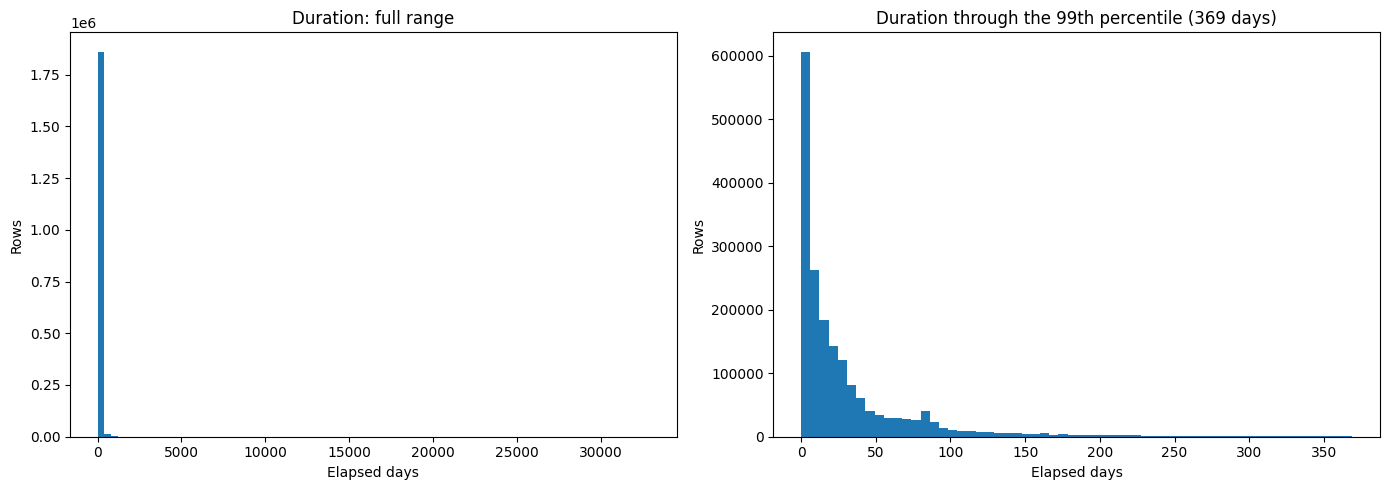

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(duration, bins=80)
axes[0].set(title='Duration: full range', xlabel='Elapsed days', ylabel='Rows')
axes[1].hist(duration[duration.le(p99)], bins=60)
axes[1].set(title=f'Duration through the 99th percentile ({p99:,.0f} days)', xlabel='Elapsed days', ylabel='Rows')
plt.tight_layout()
plt.show()

In [63]:
date_audit = pd.Series({
    'Missing/unparseable start date': df['WOStartDate'].isna().sum(),
    'Missing/unparseable end date': df['WOEndDate'].isna().sum(),
    'End before start': elapsed_days.lt(0).sum(),
    'Missing duration but valid date pair (possible recovery)': (df['WODuration'].isna() & df['valid_dates']).sum(),
    'Valid recorded target but inconsistent/missing dates': (df['valid_target'] & ~df['duration_date_consistent']).sum(),
    'Duration over one year': duration.gt(365).sum(),
}, name='Rows')
date_audit.to_frame()

,Rows
Missing/unparseable start date,0
Missing/unparseable end date,1413122
End before start,12202
Missing duration but valid date pair (possible recovery),10054
Valid recorded target but inconsistent/missing dates,61989
Duration over one year,19345


In [64]:
df.nlargest(8, 'WODuration')[['UniversityID', 'WOID', 'WODescription', 'WOStartDate', 'WOEndDate', 'WODuration']]

,UniversityID,WOID,WODescription,WOStartDate,WOEndDate,WODuration
1474971,8,WO411925,REPLACE BURNER,2016-01-14 00:00:00,2016-02-03 00:00:00,32892.0
1746177,10,30000001,DO NOT USE - ZONE 1 TROUBLE CALLS,2003-01-31 17:04:05,2020-11-24 09:37:01,6506.0
1884096,10,31303090,GRE: SERVICES REPAIRS TO INFRASTRUCTURE AND COMMON AREAS,2003-01-30 16:49:26,2020-09-23 13:07:11,6445.0
2579522,10,36000496,AND - PROVIDE MAINTENANCE OF FIRE ALARM SYSTEM,2003-02-11 11:00:24,2020-01-21 11:06:06,6188.0
2704361,10,36046048,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-07-28 07:51:07,2020-04-23 10:22:53,6114.0
2442447,10,36056807,MTHLY-BUILDING AIR COMP. MAINTENANCE INSTRUCTIONS,2003-09-01 11:16:09,2018-04-11 16:44:41,5336.0
2016992,10,36063358,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-09-22 15:20:53,2018-04-11 16:44:41,5315.0
2133116,10,36063617,MTHLY-SPLIT SYSTEM (A/C & FURNACE) MAINTENANCE INSTRUCTIONS,2003-09-22 15:44:32,2018-04-11 16:44:41,5315.0


In [65]:
cost_sum = df[['LaborCost', 'MaterialCost', 'OtherCost']].sum(axis=1, min_count=3)
cost_comparable = cost_sum.notna() & df['TotalCost'].notna()
cost_mismatch = cost_comparable & (cost_sum - df['TotalCost']).abs().gt(.05)

In [66]:
df.loc[cost_mismatch, ['WOID', 'LaborCost', 'MaterialCost', 'OtherCost', 'TotalCost']].head()

,WOID,LaborCost,MaterialCost,OtherCost,TotalCost
204343,UAF06-0010425,0.0,0.0,0.0,140.00
204401,UAF06-0010465,0.0,0.0,0.0,7270.00
204405,UAF06-0010467,0.0,0.0,0.0,23280.12
204412,UAF06-0010474,0.0,0.0,0.0,3273.36
204414,UAF06-0010476,0.0,1408.8,0.0,6840.36


Duration is strongly skewed: the median is 14 days and the 90th percentile is 86 days. About 42.3% of deduplicated rows lack recorded duration.

## 3. Compare universities and work types

We compare record counts and duration by state, university, maintenance type, and priority. Priority is treated as a local category.

In [67]:
def duration_summary(group_columns):
    return (df.loc[df['valid_target']].groupby(group_columns, dropna=False, observed=True)
            .agg(rows=('record_id', 'size'), median_days=('WODuration', 'median'),
                 p90_days=('WODuration', lambda x: x.quantile(.9)),
                 zero_pct=('WODuration', lambda x: x.eq(0).mean()*100))
            .sort_values('rows', ascending=False))

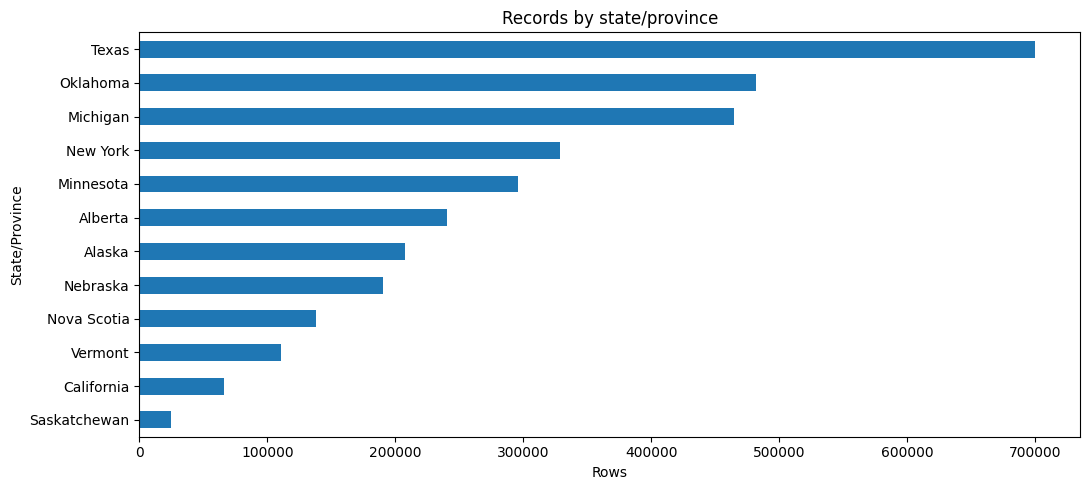

In [68]:
state_counts = df['State/Province'].fillna('Unknown').value_counts()
state_counts.sort_values().plot.barh(title='Records by state/province', xlabel='Rows')
plt.tight_layout()
plt.show()

In [69]:
duration_summary(['State/Province']).round(2)

,rows,median_days,p90_days,zero_pct
State/Province,,,,
Texas,699750,10.0,50.0,4.24
Minnesota,289975,27.0,87.0,6.72
Alberta,240168,22.0,116.0,2.59
Nebraska,187630,14.0,57.0,0.00
Nova Scotia,134421,30.0,160.0,0.00
New York,133568,36.0,216.0,0.00
Vermont,99035,3.0,94.0,27.48
California,65936,0.0,0.0,94.72
Saskatchewan,25024,7.0,71.0,19.70


In [70]:
university_summary = duration_summary(['UniversityID'])
university_summary.round(2)

,rows,median_days,p90_days,zero_pct
UniversityID,,,,
10,699750,10.0,50.0,4.24
6,289975,27.0,87.0,6.72
4,240168,22.0,116.0,2.59
9,187630,14.0,57.0,0.00
1,134421,30.0,160.0,0.00
12,133568,36.0,216.0,0.00
8,99035,3.0,94.0,27.48
2,65936,0.0,0.0,94.72
7,25024,7.0,71.0,19.70


In [71]:
duration_summary(['UniversityID', 'PPM/UPM']).round(2)

,,rows,median_days,p90_days,zero_pct
UniversityID,PPM/UPM,,,,
10,PPM,585720,12.0,49.0,3.27
6,PPM,151734,57.0,87.0,0.30
9,PPM,148704,15.0,61.0,0.00
4,UPM,142378,13.0,140.0,4.32
6,UPM,136332,7.0,71.0,13.70
10,UPM,112375,4.0,54.0,9.13
12,UPM,107671,33.0,195.0,0.00
4,PPM,97790,30.0,96.0,0.07
8,UPM,89818,3.0,82.0,28.42


In [72]:
priority_summary = duration_summary(['UniversityID', 'WOPriority'])
priority_summary.head(30).round(2)

rows  median_days  p90_days  zero_pct
UniversityID WOPriority                                         
10           1.0         346934         11.0      40.0      3.78
             3.0         189180          9.0      54.0      3.80
             2.0         116930          9.0      53.0      7.19
4            3            94609         15.0     161.0      3.64
             5            90015         30.0      96.0      0.10
9            4-ROUTINE    87077         10.0      54.0      0.00
6            42           69644         50.0      89.0      0.33
             5            61942          4.0      45.0     15.84
9            5-PM         61696         24.0      69.0      0.00
12           30.0         60744         49.0     277.0      0.00
1            3            50500         41.0     238.0      0.00
6            10           49453         10.0      76.0      9.51
             41           46392         72.0      87.0      0.24
8            3.0          42344          7.0     112.0     12.96
2            4-ROUTINE    38804          0.0       0.0     94.53
12           40.0         37627         33.0     181.0      0.00
10           4.0          36202         17.0      84.0      1.64
6            43           34852         44.0      91.0      0.32
1            2            32502         20.0     110.0      0.00
9            2-URGENT     31746          8.0      37.0      0.00
8            2.0          31068          2.0      85.0     27.94
1            1            26702         21.0     119.0      0.00
4            2            22936         19.0     148.0      2.75
             1            22381         14.0      69.0      4.57
2            2-URGENT     19784          0.0       0.0     96.45
12           50.0         18867         28.0     152.0      0.00
8            1.0          18782          0.0       5.0     66.73
12           45.0         16209         21.0     127.0      0.00
1            7            11272         24.0     139.0      0.00
10           5.0          10443         17.0     201.0      3.50

In [73]:
groups = [df.loc[df['valid_target'] & df['State/Province'].eq(s), 'WODuration'].to_numpy()
          for s in state_counts.index if s != 'Unknown']
labels = [s for s in state_counts.index if s != 'Unknown']

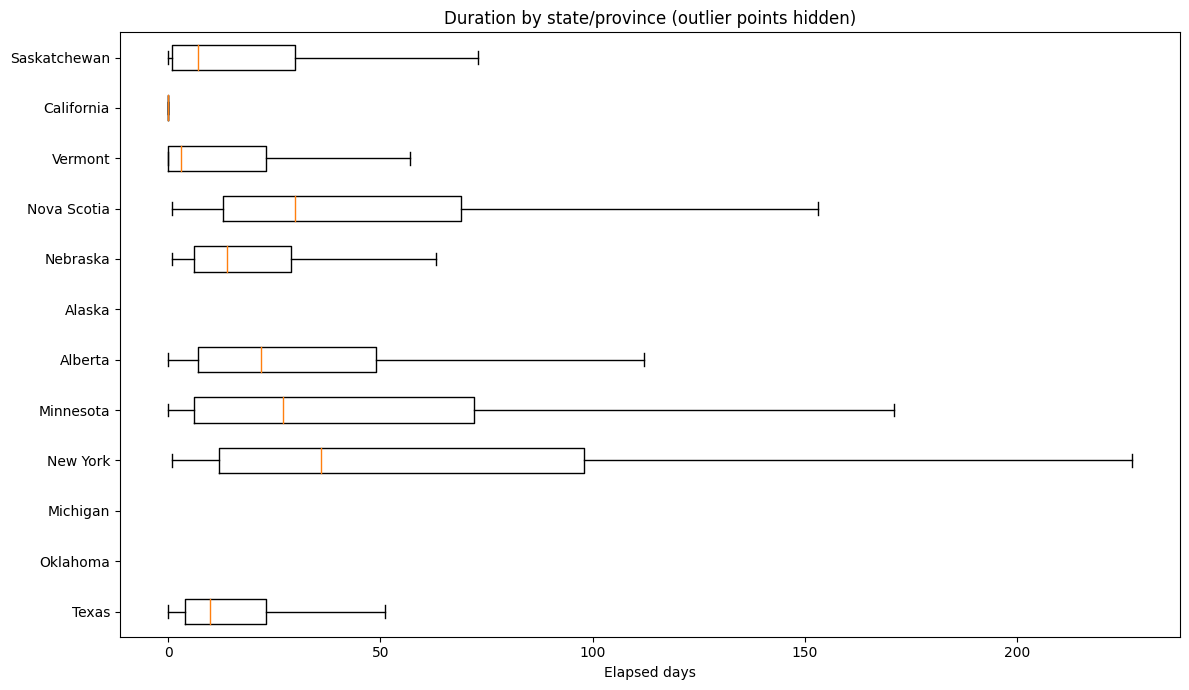

In [74]:
fig, ax = plt.subplots(figsize=(12, 7))
# Use the horizontal-boxplot argument supported by this Matplotlib version.
from inspect import signature
direction = ({'orientation': 'horizontal'} if 'orientation' in signature(ax.boxplot).parameters
             else {'vert': False})
ax.boxplot(groups, showfliers=False, **direction)
ax.set_yticks(range(1, len(labels) + 1))
ax.set_yticklabels(labels)
ax.set(title='Duration by state/province (outlier points hidden)', xlabel='Elapsed days')
plt.tight_layout()
plt.show()

University median durations range from 0 to 36 days. We need to retain university as context when comparing similar work.

## 4. Check building and classification fields

We check missing building information and the existing classification codes. Building plots use one consistent metadata record per university/building.

In [75]:
building_fields = ['Size', 'Type', 'BuiltYear', 'FCI (facility condition index)',
                   'CRV (current replacement value)', 'DMC (deferred maintenance cost)']
missing_by_university = (df.groupby('UniversityID')[building_fields].agg(lambda x: x.isna().mean()*100))
missing_by_university.round(1)

,Size,Type,BuiltYear,FCI (facility condition index),CRV (current replacement value),DMC (deferred maintenance cost)
UniversityID,,,,,,
1,4.4,4.4,4.4,4.4,4.4,4.4
10,100.0,100.0,100.0,100.0,100.0,100.0
11,100.0,100.0,5.6,100.0,100.0,100.0
12,100.0,100.0,100.0,100.0,100.0,100.0
2,100.0,100.0,100.0,100.0,100.0,100.0
3,100.0,100.0,100.0,100.0,100.0,100.0
4,100.0,100.0,100.0,100.0,100.0,100.0
5,100.0,100.0,100.0,100.0,100.0,100.0
6,0.9,0.9,0.9,1.7,0.9,1.0


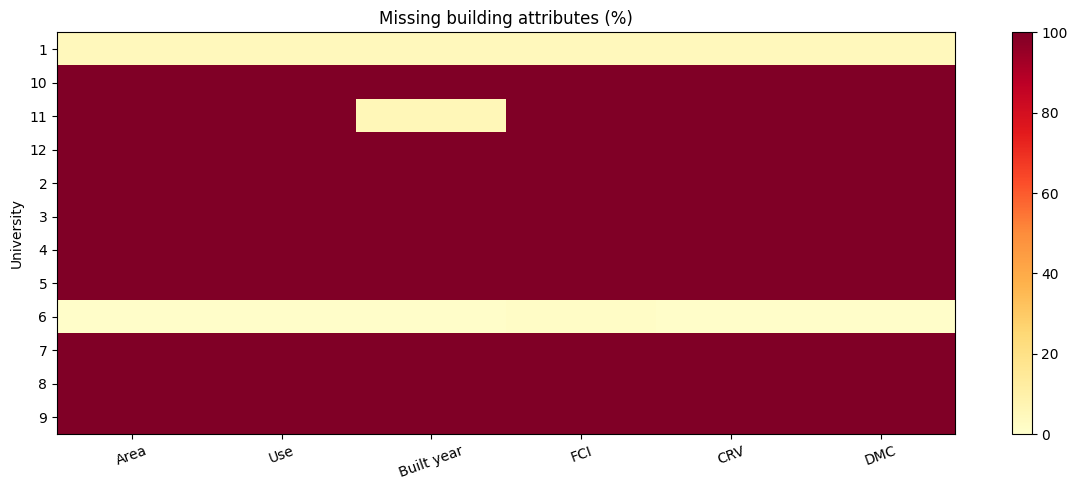

In [76]:
fig, ax = plt.subplots(figsize=(12, 5))
heat = ax.imshow(missing_by_university.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='YlOrRd')
ax.set_xticks(range(len(building_fields)), ['Area', 'Use', 'Built year', 'FCI', 'CRV', 'DMC'], rotation=20)
ax.set_yticks(range(len(missing_by_university)), missing_by_university.index)
ax.set(title='Missing building attributes (%)', ylabel='University')
fig.colorbar(heat, ax=ax)
plt.tight_layout()
plt.show()

In [77]:
df['BuildingAge'] = df['WOStartDate'].dt.year - df['BuiltYear']
negative_age_count = int(df['BuildingAge'].lt(0).sum())
df.loc[df['BuildingAge'].lt(0), 'BuildingAge'] = np.nan
nonpositive_size_count = int(df['Size'].le(0).sum())
building_meta = df.dropna(subset=['UniversityID', 'BuildingID'])[['UniversityID', 'BuildingID'] + building_fields].drop_duplicates()
building_variants = building_meta.groupby(['UniversityID', 'BuildingID']).size()
unambiguous_keys = building_variants[building_variants.eq(1)].index
building_sample = building_meta.set_index(['UniversityID', 'BuildingID']).loc[unambiguous_keys]

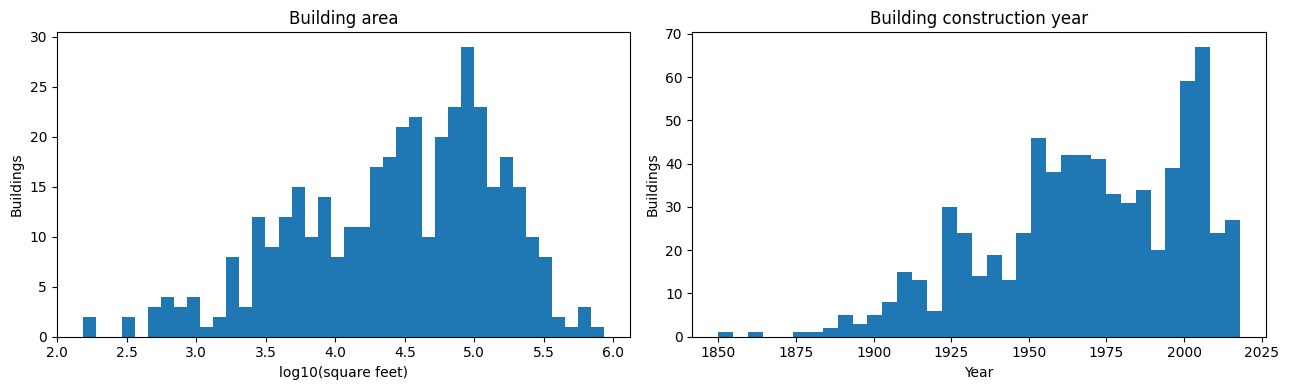

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(building_sample.loc[building_sample['Size'].gt(0), 'Size']), bins=40)
axes[0].set(title='Building area', xlabel='log10(square feet)', ylabel='Buildings')
axes[1].hist(building_sample['BuiltYear'].dropna(), bins=35)
axes[1].set(title='Building construction year', xlabel='Year', ylabel='Buildings')
plt.tight_layout()
plt.show()

In [79]:
classification_summary = pd.DataFrame({
    c: {'unique': df[c].nunique(), 'missing_pct': df[c].isna().mean()*100}
    for c in ['SystemCode', 'SubsystemCode', 'DescriptiveCode', 'Type']
}).T
classification_summary.round(2)

,unique,missing_pct
SystemCode,23.0,1.44
SubsystemCode,88.0,1.44
DescriptiveCode,470.0,1.44
Type,23.0,86.90


In [80]:
duration_summary(['SystemDescription']).head(20).round(2)

,rows,median_days,p90_days,zero_pct
SystemDescription,,,,
Electrical,557502,10.0,57.0,5.85
HVAC,489064,19.0,94.0,7.77
Plumbing,302607,13.0,85.0,9.79
Fire Protection,123976,21.0,94.0,9.45
Equipment,100709,21.0,91.0,11.42
Interior Construction,90301,7.0,80.0,12.41
Interior Finishes,45445,19.0,132.0,7.39
Exterior Enclosure,38340,13.0,91.0,7.16
General,32302,30.0,92.0,4.30


In [81]:
mapping_audit = pd.Series({
    'Subsystem codes with multiple descriptions': (df.groupby('SubsystemCode')['SubsystemDescription'].nunique().gt(1)).sum(),
    'Component codes with multiple descriptions': (df.groupby('DescriptiveCode')['ComponentDescription'].nunique().gt(1)).sum(),
    'Building keys with varying metadata': building_variants.gt(1).sum(),
    'Rows with construction after work-order start': negative_age_count,
    'Rows with nonpositive building size': nonpositive_size_count,
}, name='Count')
mapping_audit.to_frame()

,Count
Subsystem codes with multiple descriptions,65
Component codes with multiple descriptions,1
Building keys with varying metadata,148
Rows with construction after work-order start,598
Rows with nonpositive building size,0


In [82]:
for predictor in ['Size', 'BuildingAge']:
    usable = df.loc[df['valid_target'] & df[predictor].notna(), [predictor, 'WODuration']].copy()
    if predictor == 'Size':
        usable = usable.loc[usable[predictor].gt(0)]
    usable['band'] = pd.qcut(usable[predictor], q=5, duplicates='drop')
    display(usable.groupby('band', observed=True).agg(rows=('WODuration', 'size'),
        median_days=('WODuration', 'median')).rename_axis(f'{predictor} band'))
del usable

,rows,median_days
Size band,,
"(152.999, 46114.0]",85889,34.0
"(46114.0, 94988.0]",80886,29.0
"(94988.0, 155439.0]",83406,26.0
"(155439.0, 259989.0]",86568,27.0
"(259989.0, 862133.0]",79216,22.0


,rows,median_days
BuildingAge band,,
"(-0.001, 25.0]",84001,29.0
"(25.0, 46.0]",87127,26.0
"(46.0, 57.0]",80772,29.0
"(57.0, 71.0]",81050,26.0
"(71.0, 169.0]",82421,29.0


Building area and use are missing for about 86.9% of rows. These are secondary inputs, and the classification fields give us a useful baseline.

## 5. Build and examine the text inputs

We compare the work description alone with the work description plus system, subsystem, and component context. We normalize case and whitespace for grouping, while keeping numbers and maintenance intervals.

In [83]:
df['text_wo'] = df['WODescription'].fillna('')
df['description_key'] = df['text_wo'].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()
df['has_description'] = df['description_key'].ne('')
df['text_context'] = ''
for column in ['WODescription', 'SystemDescription', 'SubsystemDescription', 'ComponentDescription']:
    values = df[column].fillna('').str.strip()
    df['text_context'] += np.where(df['text_context'].ne('') & values.ne(''), '\n', '') + values

description_counts = df.loc[df['description_key'].ne(''), 'description_key'].value_counts()
exact_description_count = df['WODescription'].nunique()
text_quality = pd.DataFrame({
    'missing_or_blank_rows': [df['text_wo'].str.strip().eq('').sum(), df['text_context'].str.strip().eq('').sum()],
    'median_characters': [df['text_wo'].str.len().median(), df['text_context'].str.len().median()],
    'p90_characters': [df['text_wo'].str.len().quantile(.9), df['text_context'].str.len().quantile(.9)],
}, index=['Description only', 'Description with context'])
text_quality

,missing_or_blank_rows,median_characters,p90_characters
Description only,914,50.0,138.0
Description with context,4,108.0,192.0


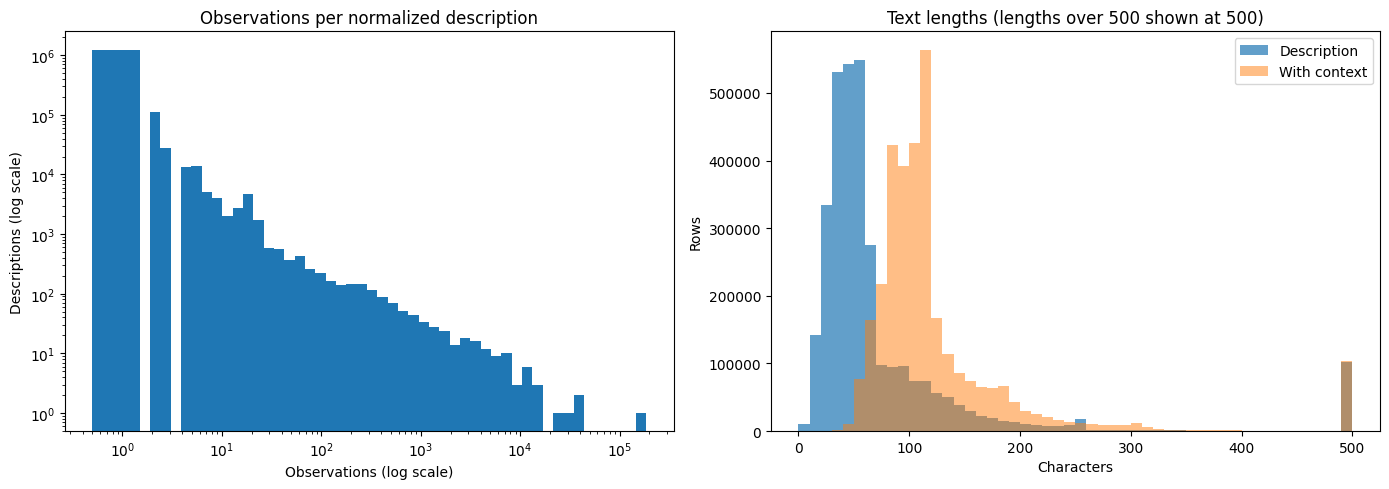

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
max_count = max(2, int(description_counts.max()))
bins = np.unique(np.r_[.5, np.geomspace(1.5, max_count+.5, 50)])
axes[0].hist(description_counts, bins=bins)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set(title='Observations per normalized description', xlabel='Observations (log scale)', ylabel='Descriptions (log scale)')
axes[1].hist(df['text_wo'].str.len().clip(upper=500), bins=50, alpha=.7, label='Description')
axes[1].hist(df['text_context'].str.len().clip(upper=500), bins=50, alpha=.5, label='With context')
axes[1].set(title='Text lengths (lengths over 500 shown at 500)', xlabel='Characters', ylabel='Rows')
axes[1].legend()
plt.tight_layout()
plt.show()

In [85]:
description_groups = df.loc[df['valid_target'] & df['description_key'].ne(''),
    ['description_key', 'record_id', 'UniversityID', 'WODuration', 'DescriptiveCode']].groupby('description_key')
description_summary = (description_groups.agg(
        rows=('record_id', 'size'), universities=('UniversityID', 'nunique'),
        median_days=('WODuration', 'median'), components=('DescriptiveCode', 'nunique')))
description_quantiles = description_groups['WODuration'].quantile([.25, .75]).unstack()
description_summary['q25'] = description_quantiles[.25]
description_summary['q75'] = description_quantiles[.75]
del description_groups, description_quantiles
description_summary['iqr_days'] = description_summary['q75'] - description_summary['q25']
description_summary.nlargest(12, 'rows').round(2)

,rows,universities,median_days,components,q25,q75,iqr_days
description_key,,,,,,,
monthly emergency&exit light inspection (1x month),185311,1,8.0,1,4.0,19.0,15.0
monthly 000 emergency light inspection (1x month),40710,1,16.0,1,8.0,31.0,23.0
general material condition: work performed on equipment or a property,31234,1,0.0,113,0.0,0.0,0.0
supply / return / interlocked exhaust fan inspection,22439,1,79.0,11,65.0,87.0,22.0
quarterly fan pm (all stand alone fans),16304,1,15.0,1,7.0,29.0,22.0
safety shower and eyewash fountain inspection annually.,11554,1,83.0,3,72.0,85.0,13.0
strobe fume fan inspection,10787,1,76.0,1,56.0,85.0,29.0
098: light emrg (1x month),8740,1,14.0,1,8.0,22.0,14.0
annual safety eyewash & shower pm,8580,1,7.0,1,5.0,17.0,12.0


In [86]:
repeated = description_summary.loc[description_summary['rows'].ge(5)]
scatter_sample = repeated.sample(min(20000, len(repeated)), random_state=42)

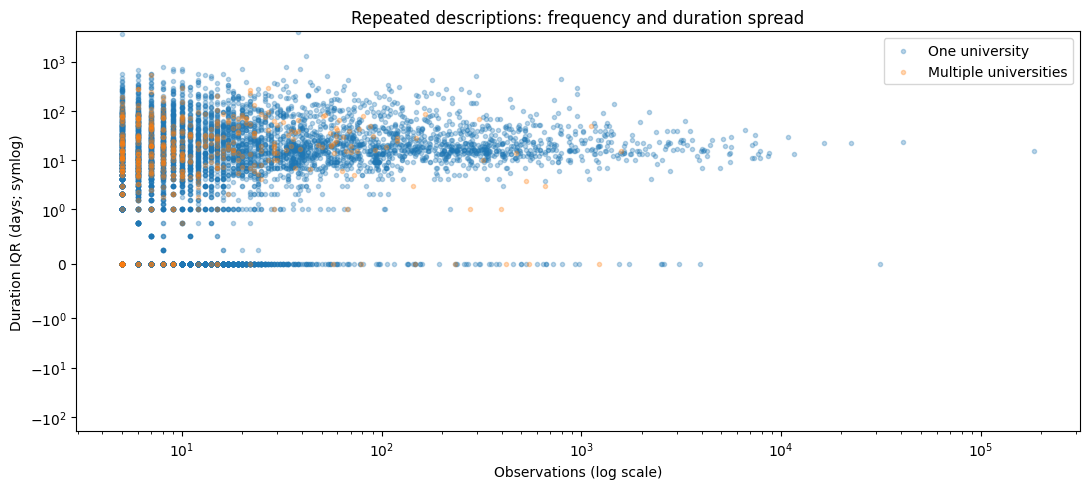

In [87]:
fig, ax = plt.subplots()
for shared, label in [(False, 'One university'), (True, 'Multiple universities')]:
    part = scatter_sample.loc[scatter_sample['universities'].gt(1).eq(shared)]
    ax.scatter(part['rows'], part['iqr_days'], s=9, alpha=.3, label=label)
ax.set_xscale('log')
ax.set_yscale('symlog', linthresh=1)
ax.set(title='Repeated descriptions: frequency and duration spread', xlabel='Observations (log scale)', ylabel='Duration IQR (days; symlog)')
ax.legend()
plt.tight_layout()
plt.show()

In [88]:
df[['text_wo', 'text_context']].sample(5, random_state=42)

,text_wo,text_context
2510682,MONTHLY EMERGENCY&EXIT LIGHT INSPECTION (1X MONTH),MONTHLY EMERGENCY&EXIT LIGHT INSPECTION (1X MONTH) Electrical Lighting and Branch Wiri...
2529739,ANNUAL 092 I&C INSPECTION-PM ROUTE,"ANNUAL 092 I&C INSPECTION-PM ROUTE HVAC Distribution Systems Air Handler, Exhaust/Mult..."
1294606,159//215/SINK TRAP IS LEAKING - REPAIR,159//215/SINK TRAP IS LEAKING - REPAIR Plumbing Plumbing Fixtures Sink
663859,BACKFLOW PREVENTER-ANNUAL TESTING,BACKFLOW PREVENTER-ANNUAL TESTING Plumbing Domestic Water Distribution Backflow Preventor
3433729,MM 8111 Jammed door,MM 8111 Jammed door Interior Construction Interior Doors Door Hardware


About 86.8% of normalized descriptions appear once. This makes similarity between different descriptions important to test.

## 6. Check time patterns and split the data

We look for changes in workload and batches of orders closed together. Training uses earlier orders with known outcomes; validation and test use later start dates.

In [89]:
monthly = (df.loc[df['valid_target'] & df['WOStartDate'].notna()]
    .groupby(df['WOStartDate'].dt.to_period('M'))
    .agg(rows=('record_id', 'size'), median_days=('WODuration', 'median')))

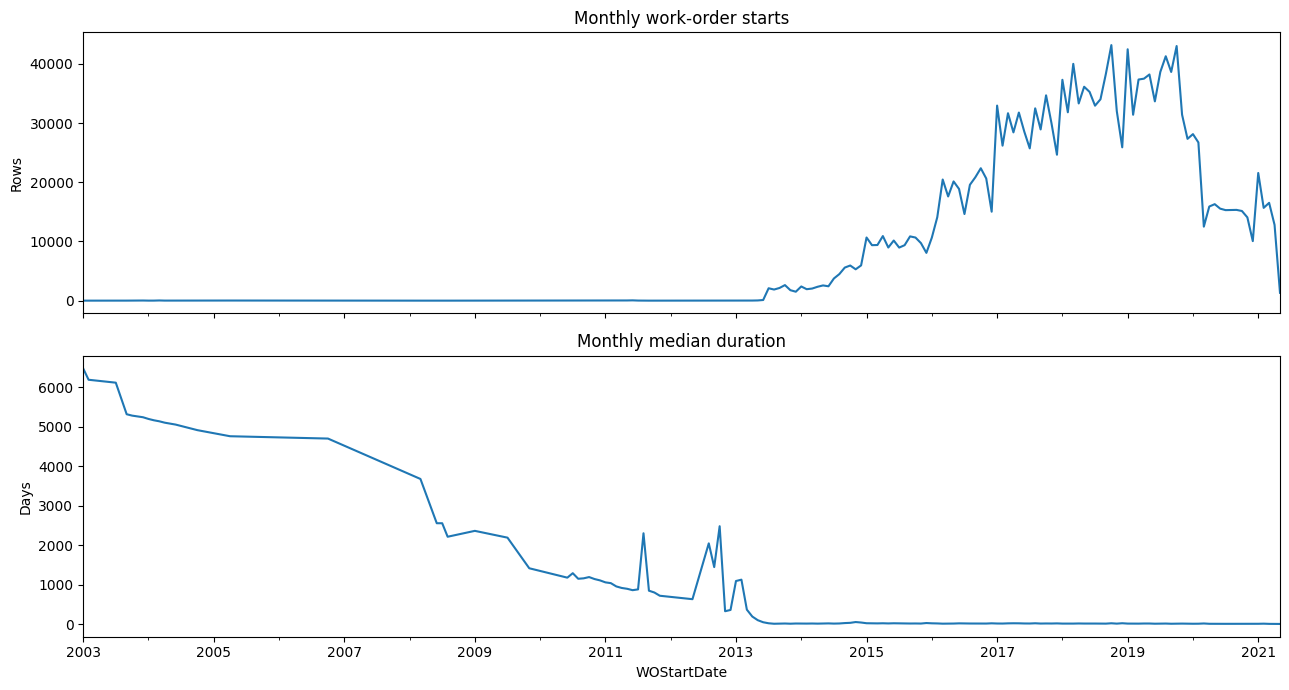

In [90]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
monthly['rows'].plot(ax=axes[0], title='Monthly work-order starts', ylabel='Rows')
monthly['median_days'].plot(ax=axes[1], title='Monthly median duration', ylabel='Days')
plt.tight_layout()
plt.show()

In [91]:
close_days = df['WOEndDate'].dt.floor('D')
closure_batches = (df.assign(close_day=close_days).dropna(subset=['close_day'])
    .groupby(['UniversityID', 'close_day']).size().nlargest(10).rename('orders_closed'))
closure_batches.to_frame()

orders_closed
UniversityID close_day                
10           2018-09-07           2967
             2020-04-08           2512
             2019-04-19           2243
             2017-06-13           1663
             2019-06-13           1651
             2017-09-06           1591
             2017-06-20           1565
             2019-01-28           1467
             2017-10-13           1461
             2020-03-18           1455

In [92]:
df['eligible'] = (df['valid_target'] & df['duration_date_consistent']
    & ~df['duplicate_order_key'] & ~df['missing_order_key'] & df['has_description'])
eligible_dates = df.loc[df['eligible'], 'WOStartDate']
TRAIN_CUTOFF = eligible_dates.quantile(.70).floor('D')
TEST_CUTOFF = eligible_dates.quantile(.85).floor('D')
assert TRAIN_CUTOFF < TEST_CUTOFF, 'Not enough distinct dates for a chronological split.'
df['split'] = 'excluded'
df.loc[df['eligible'] & df['WOStartDate'].lt(TRAIN_CUTOFF) & df['WOEndDate'].lt(TRAIN_CUTOFF), 'split'] = 'train'
df.loc[df['eligible'] & df['WOStartDate'].ge(TRAIN_CUTOFF) & df['WOStartDate'].lt(TEST_CUTOFF)
       & df['WOEndDate'].lt(TEST_CUTOFF), 'split'] = 'validation'
df.loc[df['eligible'] & df['WOStartDate'].ge(TEST_CUTOFF), 'split'] = 'test'

In [93]:
exclusion_rules = [
    (~df['valid_target'].fillna(False), 'Missing/invalid duration'),
    (df['missing_order_key'], 'Missing university/order ID'),
    (df['duplicate_order_key'], 'Repeated university/order ID'),
    (~df['has_description'].fillna(False), 'Missing work description'),
    (~df['duration_date_consistent'].fillna(False), 'Missing/inconsistent dates'),
    (df['split'].eq('excluded'), 'Outcome unavailable at split cutoff'),
]
df['exclusion_reason'] = 'Included'
for condition, reason in exclusion_rules:
    first_match = condition.fillna(False) & df['exclusion_reason'].eq('Included')
    df.loc[first_match, 'exclusion_reason'] = reason
df['exclusion_reason'].value_counts().rename('Rows (first applicable reason)').to_frame()

,Rows (first applicable reason)
exclusion_reason,
Included,1510811
Missing/invalid duration,1373390
Repeated university/order ID,276322
Outcome unavailable at split cutoff,57703
Missing/inconsistent dates,29358
Missing university/order ID,816
Missing work description,497


In [94]:
split_summary = df.groupby('split').agg(rows=('record_id', 'size'), start_min=('WOStartDate', 'min'),
    start_max=('WOStartDate', 'max'), median_days=('WODuration', 'median'))
split_summary

,rows,start_min,start_max,median_days
split,,,,
excluded,1738086,2002-09-06 12:09:12,2021-05-28 00:00:00,24.0
test,235888,2019-11-20 00:00:00,2021-05-23 19:26:36,7.0
train,1065435,2003-09-01 11:16:09,2019-03-24 00:00:00,16.0
validation,209488,2019-03-25 00:00:00,2019-11-19 09:17:43,10.0


In [95]:
pd.crosstab(df['UniversityID'], df['split'])

split,excluded,test,train,validation
UniversityID,,,,
1,16379,1538,107416,12842
10,18410,196811,398534,86208
11,482141,0,0,0
12,309373,12393,178,6379
2,63959,1975,2,0
3,207488,0,0,0
4,4900,2641,202090,30537
5,464250,0,0,0
6,69850,11335,168575,46304


In [96]:
boundary_unfinished = df['eligible'] & df['split'].eq('excluded')

Training outcomes must be known before March 25, 2019. Test orders start November 20, 2019; orders still unfinished at a split boundary are excluded from that earlier period.

## 7. Prepare task-level features

A task is a normalized description plus its classification codes. We create one row per training task, with separate text and aggregate inputs. Duration summaries are kept apart for later evaluation.

In [97]:
task_key_columns = ['description_key', 'SystemCode', 'SubsystemCode', 'DescriptiveCode']
task_keys = df[task_key_columns].fillna('').astype('string')
unique_task_keys = task_keys.drop_duplicates().copy()
unique_task_keys['task_id'] = pd.util.hash_pandas_object(unique_task_keys, index=False).astype('uint64')
assert unique_task_keys['task_id'].is_unique, 'Task hash collision: use a longer hash before export.'
df['task_id'] = pd.util.hash_pandas_object(task_keys, index=False).astype('uint64')
del task_keys, unique_task_keys
train = df.loc[df['split'].eq('train')].copy()
train['is_ppm'] = train['PPM/UPM'].map({'PPM': 1., 'UPM': 0.})
train['log_building_size'] = np.log1p(train['Size'].where(train['Size'].gt(0)))
train['size_missing'] = train['log_building_size'].isna()
train['age_missing'] = train['BuildingAge'].isna()
train['maintenance_type_missing'] = train['is_ppm'].isna()
train['building_key'] = train['UniversityID'].fillna('') + '|' + train['BuildingID'].fillna('')
train.loc[train['BuildingID'].isna(), 'building_key'] = pd.NA
task_text = (train.sort_values(['WOStartDate', 'record_id']).drop_duplicates('task_id')
    [['task_id', 'text_wo', 'text_context', 'description_key', 'SystemCode', 'SubsystemCode', 'DescriptiveCode']]
    .sort_values('task_id').reset_index(drop=True))

In [98]:
task_aggregates = (train.groupby('task_id').agg(
    history_count=('record_id', 'size'), university_count=('UniversityID', 'nunique'),
    building_count=('building_key', 'nunique'), ppm_share=('is_ppm', 'mean'),
    median_log_building_size=('log_building_size', 'median'),
    median_building_age=('BuildingAge', 'median'),
    building_size_missing_share=('size_missing', 'mean'),
    building_age_missing_share=('age_missing', 'mean'),
    maintenance_type_missing_share=('maintenance_type_missing', 'mean'))
    .reset_index().sort_values('task_id').reset_index(drop=True))
task_aggregates['log_history_count'] = np.log1p(task_aggregates['history_count'])
task_aggregates['log_building_count'] = np.log1p(task_aggregates['building_count'])
numeric_feature_columns = ['log_history_count', 'university_count', 'log_building_count', 'ppm_share',
    'median_log_building_size', 'median_building_age', 'building_size_missing_share',
    'building_age_missing_share', 'maintenance_type_missing_share']
aggregate_features = task_aggregates[['task_id'] + numeric_feature_columns]
task_outcomes = (train.groupby('task_id').agg(training_median_days=('WODuration', 'median'),
    training_mean_days=('WODuration', 'mean'), training_std_days=('WODuration', 'std')).reset_index())

In [99]:
record_columns = ['record_id', 'task_id', 'UniversityID', 'WOID', 'BuildingID', 'State/Province',
    'WOPriority', 'PPM/UPM', 'Type', 'Size', 'BuildingAge', 'SystemCode', 'SubsystemCode',
    'DescriptiveCode', 'text_wo', 'text_context', 'WOStartDate', 'split']
model_records = df.loc[df['split'].ne('excluded'), record_columns].copy()
model_records['StartMonth'] = model_records['WOStartDate'].dt.month
model_records['StartWeekday'] = model_records['WOStartDate'].dt.dayofweek
model_records['StartYear'] = model_records['WOStartDate'].dt.year
model_records['known_training_task'] = model_records['task_id'].isin(task_text['task_id'])
outcomes = df.loc[df['split'].ne('excluded'), ['record_id', 'task_id', 'WOEndDate', 'WODuration', 'split']].copy()
task_text.head(3)

,task_id,text_wo,text_context,description_key,SystemCode,SubsystemCode,DescriptiveCode
0,9634247750185,PLEASE DE-ENERGIZE (DEPT) OUTLETS VOTEY 120 - DAVIS ZONE,PLEASE DE-ENERGIZE (DEPT) OUTLETS VOTEY 120 - DAVIS ZONE Electrical Lighting and Branc...,please de-energize (dept) outlets votey 120 - davis zone,D50,D5020,D5020REC
1,54467825815927,250-ALRM00 FIRE PANEL TROUBLE,250-ALRM00 FIRE PANEL TROUBLE Electrical Communications & Security Annunciation Panel,250-alrm00 fire panel trouble,D50,D5030,D5030ANP
2,101560511309779,BH - FIRE DOOR WON'T CLOSE-SEE DETAILS,BH - FIRE DOOR WON'T CLOSE-SEE DETAILS Fire Protection Fire Protection Specialities Fi...,bh - fire door won't close-see details,D40,D4030,D4030FDO


In [100]:
aggregate_features.head(5)

,task_id,log_history_count,university_count,log_building_count,ppm_share,median_log_building_size,median_building_age,building_size_missing_share,building_age_missing_share,maintenance_type_missing_share
0,9634247750185,0.693147,1,0.000000,0.0,NaN,NaN,1.0,1.0,0.0
1,54467825815927,0.693147,1,0.693147,0.0,11.798864,9.0,0.0,0.0,0.0
2,101560511309779,0.693147,1,0.693147,0.0,12.074305,44.0,0.0,0.0,0.0
3,114668278416659,0.693147,1,0.693147,0.0,NaN,NaN,1.0,1.0,0.0
4,161597297449972,0.693147,1,0.693147,0.0,NaN,NaN,1.0,1.0,0.0


In [101]:
task_aggregates['history_count'].describe(percentiles=[.5, .9, .99]).to_frame()

,history_count
count,467618.000000
mean,2.278430
std,112.024354
min,1.000000
50%,1.000000
90%,1.000000
99%,4.000000
max,56315.000000


In [102]:
novelty = model_records.groupby('split')['known_training_task'].agg(['size', 'mean']).rename(columns={'size': 'rows', 'mean': 'known_task_share'})
novelty

,rows,known_task_share
split,,
test,235888,0.701753
train,1065435,1.000000
validation,209488,0.573713


The current export contains 467,618 training tasks. About 96.8% have one observation under the description-plus-classification task definition.

## 8. Save the datasets

We save the text inputs, aggregate features, work-order records, outcomes, and exclusion audit to `data/clustering/`. Join tasks on `task_id` and work orders on `record_id`.

In [103]:
import sys
sys.path.insert(0, str(PROJECT_DIR))
from pipeline_utils import save_exploration_exports, exploration_readme
export_tables = {
    'tasks_text_wo_train.parquet': task_text[['task_id', 'text_wo']],
    'tasks_text_context_train.parquet': task_text[['task_id', 'text_context']],
    'tasks_aggregates_train.parquet': aggregate_features,
    'task_lookup_train.parquet': task_text,
    'task_outcomes_train.parquet': task_outcomes,
    'work_order_features.parquet': model_records,
    'work_order_outcomes.parquet': outcomes,
    'record_audit.parquet': df[['record_id', 'UniversityID', 'WOID', 'valid_target', 'valid_dates',
        'duration_date_consistent', 'duplicate_order_key', 'missing_order_key', 'has_description',
        'eligible', 'split', 'exclusion_reason']],
}
assert task_text['task_id'].equals(aggregate_features['task_id'])
assert model_records['record_id'].is_unique and outcomes['record_id'].is_unique
assert model_records['record_id'].equals(outcomes['record_id'])

In [104]:
assert train['WOEndDate'].lt(TRAIN_CUTOFF).all()
assert not set(['WODuration', 'LaborHours', 'LaborCost', 'TotalCost', 'WOEndDate']) & set(aggregate_features.columns)

In [105]:
manifest = {
    'source': 'https://data.mendeley.com/datasets/cb8d2nsjss/1',
    'source_file_bytes': DATA_PATH.stat().st_size,
    'target': 'WODuration', 'target_unit': 'elapsed days',
    'train_outcomes_known_before': TRAIN_CUTOFF.isoformat(),
    'test_start': TEST_CUTOFF.isoformat(),
    'task_definition': task_key_columns,
    'aggregate_feature_columns': numeric_feature_columns,
    'raw_rows': len(df_raw), 'exact_duplicates_removed': exact_duplicate_count,
    'policy': 'Nonnegative target, date agreement within one day, nonblank description, unambiguous university/order key; completed training/validation outcomes available before next cutoff; no upper-duration trimming.',
    'warnings': [
        'All clustering profiles use only the training window. Rebuild inside earlier validation folds.',
        'Task outcome summaries are interpretation targets, not clustering/predictor inputs.',
        'Work-order features may contain university-local categories and missing building attributes.',
        'No claim of cold-start performance: evaluate unseen tasks separately.',
        'Completed-order selection and text updated after creation may bias duration evaluation.',
        'Task IDs are pandas 64-bit hashes of normalized text and codes; source indices define record_id.',
    ],
    'versions': {'pandas': pd.__version__, 'numpy': np.__version__},
    'files': {},
}

In [106]:
readme = exploration_readme(TRAIN_CUTOFF, TEST_CUTOFF)
summaries = {'field_quality.csv': field_quality, 'target_quality.csv': target_quality,
             'university_duration_summary.csv': university_summary, 'split_summary.csv': split_summary}
export_summary = save_exploration_exports(OUTPUT_DIR, export_tables, manifest, summaries, readme)
export_summary

,rows,bytes
tasks_text_wo_train.parquet,467618,30543430
tasks_text_context_train.parquet,467618,36927776
tasks_aggregates_train.parquet,467618,5191379
task_lookup_train.parquet,467618,89446490
task_outcomes_train.parquet,467618,5459779
work_order_features.parquet,1510811,173455500
work_order_outcomes.parquet,1510811,24261741
record_audit.parquet,3248897,30825946


Eight tables are saved with separate feature and outcome files. The audit records why orders were excluded.

## For the presentation

I will use the duration distribution and description-frequency plot to explain the problem. The other checks support the data choices. Family examples and the model comparison will come from the next notebooks.